# PSF distiller fluorescent beads

## Import packages and load data

In [53]:
from brighteyes.imaging.io.mcs import metadata_print, load
from brighteyes.imaging.analysis.Graph_lib import ShowDataset, PlotShiftVectors, ShowFingerprint
from brighteyes.imaging.analysis.APR_lib import APR, Reassignment, ShiftVectors
import brighteyes.imaging.analysis.Tools_lib as tool
import brighteyes.imaging.simulation.PSF_sim as sim

import brighteyes.imaging.psf_distiller.distiller as dis
from brighteyes.imaging.s2ism.psf_estimator import GridFinder
from brighteyes.spectroscopy.tools.csv2array import array2csv, csv2array

import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import gaussian

In [5]:
folder = r'Y:\Data MMS server\ISMFLUX\2025-09-01_test_psf_distiller_beads'
file = '02_data-01-09-2025-16-35-44.h5'
data, mdata = load(folder + '\\' + file)
data = np.squeeze(np.sum(data, (4)))
print(np.shape(data))
data_sumc = np.sum(data, 2)

(250, 250, 25)


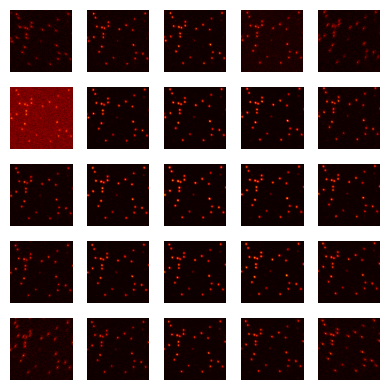

In [6]:
_ = ShowDataset(data, figsize=(4,4))

## Pre-processing

### Select particles in image

- Sample: mixture of fixed gold nanoparticles and fluorescent beads (20 nm). The gold nanoparticles are used to keep the sample stable in 3D while 2D scanning a large FOV of fluorescent beads.
- Data: single image (Nx, Ny, Nc) of many beads, pixel size 40 nm. The user has to select the good beads, which are overlayed on top of each other to increase the SNR.

In [8]:
click = False
n_beads = 15
if click:
    # ask the user to manually click on 15 beads in the image
    %matplotlib qt
    plt.figure()
    plt.imshow(data_sumc)
    clicked_points = plt.ginput(n_beads, show_clicks=True)
    clicked_points = np.asarray(clicked_points)
    #array2csv(clicked_points, 'clicked_points.csv')
    click = False
else:
    # read the clicked points from a file
    clicked_points = csv2array('clicked_points.csv')

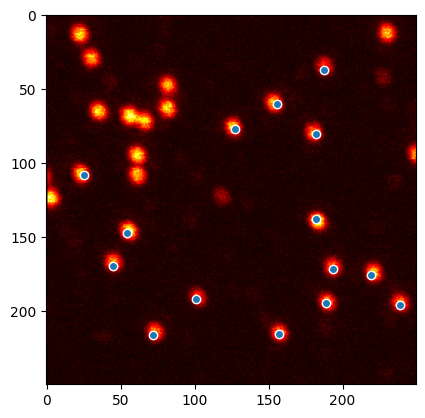

In [39]:
plt.figure()
plt.imshow(data_sumc, cmap='hot')
plt.scatter(clicked_points[:,0], clicked_points[:,1], color=None, edgecolor='white')

### Add padding

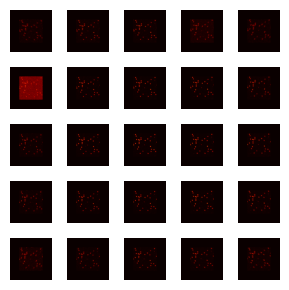

In [11]:
pad = 100
nx = np.shape(data)[0]
nc = np.shape(data)[2]
data_padded = np.zeros((nx+2*pad, nx+2*pad, nc))
data_padded[pad:pad+nx, pad:pad+nx, :] = data

clicked_points_pad = clicked_points + pad

_ = ShowDataset(data_padded, figsize=(3,3))

In [12]:
range_particle = 18
single_beads = np.zeros((n_beads, 2*range_particle, 2*range_particle, 25))
for i in range(n_beads):
    bead_coord = clicked_points_pad[i]
    xmin = int(bead_coord[0] - range_particle)
    xmax = int(bead_coord[0] + range_particle)
    ymin = int(bead_coord[1] - range_particle)
    ymax = int(bead_coord[1] + range_particle)
    single_beads[i,] = data_padded[ymin:ymax, xmin:xmax, :]

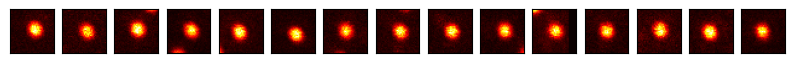

In [25]:
fig, axes = plt.subplots(1, n_beads, figsize=(10, 3))
for i in range(n_beads):
    axes[i].imshow(np.sum(single_beads[i,], -1), cmap='hot')
    axes[i].set_xticks([])
    axes[i].set_yticks([])

### Register particles based on sum5x5

Find shifts between particles

In [27]:
sum5 = np.zeros((2*range_particle, 2*range_particle, n_beads))
for i in range(n_beads):
    sum5[:,:,i] = np.sum(single_beads[i,], -1)

pxsize = 40
shift_vec, result_ism_pc = APR(sum5, 10, 0, pxsize)

Apply shift to particles

In [29]:
single_beads_registered = np.zeros((n_beads, 2*range_particle, 2*range_particle, 25))
for i in range(n_beads):
    single_beads_registered[i,] = Reassignment(np.tile([shift_vec[i,:]/pxsize], (25,1)), single_beads[i,])
#single_beads_registered = np.load('02_single_beads_registered.npy')

Sum all particles

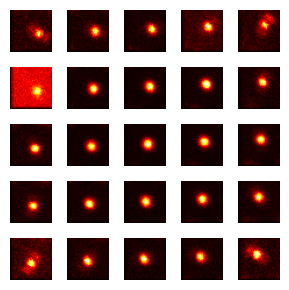

In [32]:
exp_psf = np.sum(single_beads_registered, 0)
_ = ShowDataset(exp_psf, figsize=(3,3))

### Center PSFs

In [40]:
data = np.empty_like(exp_psf)
nx = np.shape(exp_psf)[0]
ny = nx
cx, cy, cc = tool.ArgMaxND(gaussian(exp_psf, 4, channel_axis = -1))[0]
sx, sy = nx//2 - cx, ny//2 - cy
data = np.roll(exp_psf, [sx, sy], axis = (0, 1))
data = data/data.sum()

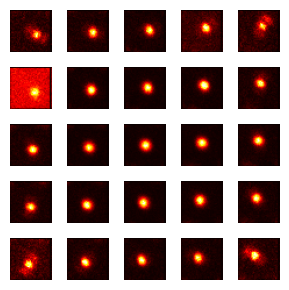

In [42]:
h = ShowDataset(data, figsize=(3,3))

### Crop and filter PSFs

Crop the PSFs to remove boundary artifacts and apply background filter to remove high dark count rate

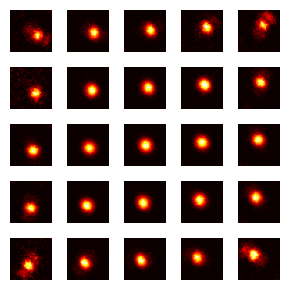

In [44]:
ex_psf_cropped = data[3:-3,3:-3,:]
bg = np.asarray([np.median(ex_psf_cropped[:,:,k]) for k in range(25)])
exp_psf_filtered = np.clip(ex_psf_cropped - bg, 0, None) #bg[np.newaxis, np.newaxis, :]
exp_psf_filtered = exp_psf_filtered/exp_psf_filtered.sum()
_ = ShowDataset(exp_psf_filtered, figsize=(3,3))

(<Figure size 640x480 with 1 Axes>, <Axes: >)

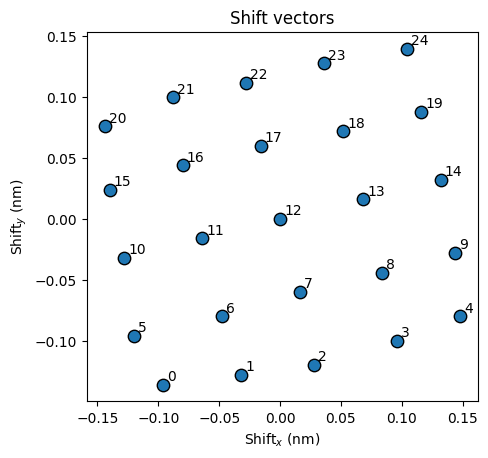

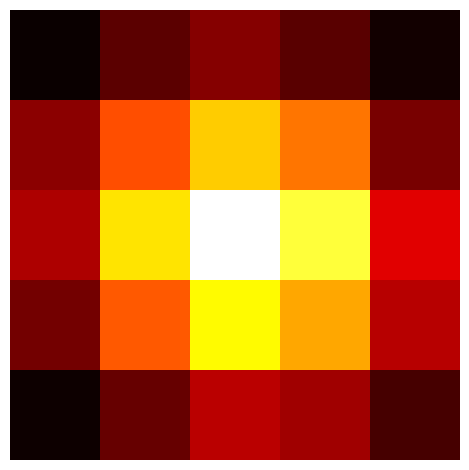

In [54]:
shift_vectors, _ = ShiftVectors(exp_psf_filtered, 10, 12)
PlotShiftVectors(shift_vectors, mdata.dx)
ShowFingerprint(exp_psf_filtered)

## Perform fit

pxsizex       40.00
pxsizez       50.00
Nx            30.00
Nz            1.00
pxpitch       75000.00
pxdim         70000.00
pinhole_shape circle
geometry      rect
N             5.00
M             500.00
rotation      4.95
mirroring     -1.00
name          
shift         52.89


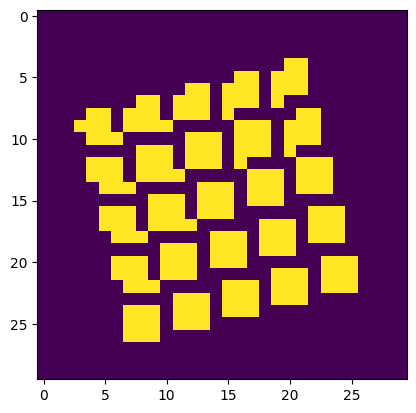

In [55]:
data = exp_psf_filtered

process = 'cpu'
exPar = sim.simSettings()
exPar.na = 1.4   # numerical aperture
exPar.wl = 640   # wavelength [nm]
exPar.gamma = 45  # parameter describing the light polarization
exPar.beta = 90  # parameter describing the light polarization
exPar.n = 1.5
exPar.mask_sampl = 101 #128

emPar = exPar.copy()
emPar.wl = 660

grid = sim.GridParameters()
grid.pxsizex = 40 # <------------------------- to fill in (nm)
grid.Nx = data.shape[0]

grid.pxpitch = 75e3
grid.pxdim = 70e3
grid.pinhole_shape = 'circle'
grid.N = 5
grid.M = 500 #450

grid_fit = GridFinder(grid)
grid_fit.estimate(data, exPar.wl, emPar.wl, exPar.na)
grid_fit.M = grid.M
grid_fit.Print()

spad = sim.custom_detector(grid_fit, 'cpu')

plt.figure()
plt.imshow(spad.cpu().detach().numpy().sum(-1))

In [106]:
result, history = dis.fit_psf(data, exPar, emPar, grid, spad, bead_radius=40, independent_wavefront=True, num_starts=100, max_iter=1000)


Optimization: 1/100
Iteration: 1000/1000	Loss: 2.15E-01
Optimization: 2/100
Iteration: 1000/1000	Loss: 2.13E-01
Optimization: 3/100
Iteration: 1000/1000	Loss: 2.19E-01
Optimization: 4/100
Iteration: 1000/1000	Loss: 2.76E-01
Optimization: 5/100
Iteration: 1000/1000	Loss: 2.56E-01
Optimization: 6/100
Iteration: 1000/1000	Loss: 2.52E-01
Optimization: 7/100
Iteration: 1000/1000	Loss: 2.04E-01
Optimization: 8/100
Iteration: 1000/1000	Loss: 2.11E-01
Optimization: 9/100
Iteration: 1000/1000	Loss: 2.19E-01
Optimization: 10/100
Iteration: 1000/1000	Loss: 2.50E-01
Optimization: 11/100
Iteration: 1000/1000	Loss: 2.41E-01
Optimization: 12/100
Iteration: 1000/1000	Loss: 2.07E-01
Optimization: 13/100
Iteration: 1000/1000	Loss: 1.94E-01
Optimization: 14/100
Iteration: 1000/1000	Loss: 1.96E-01
Optimization: 15/100
Iteration: 1000/1000	Loss: 2.49E-01
Optimization: 16/100
Iteration: 1000/1000	Loss: 3.15E-01
Optimization: 17/100
Iteration: 1000/1000	Loss: 2.12E-01
Optimization: 18/100
Iteration: 1000/10

Text(0, 0.5, 'Loss')

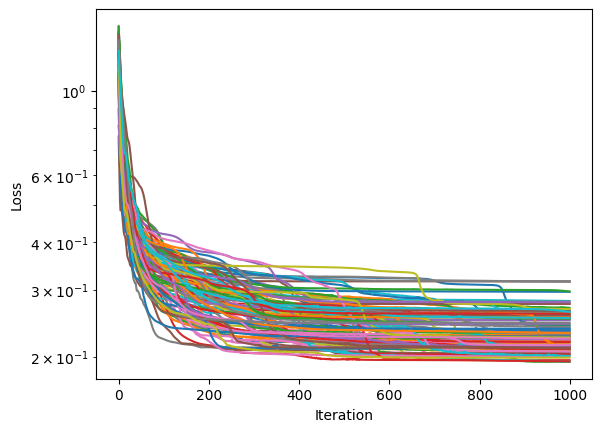

In [107]:
plt.figure()
plt.semilogy(np.asarray(history).T)
plt.xlabel('Iteration')
plt.ylabel('Loss')

In [108]:
zer_max = 15
zernike_idx = np.arange(zer_max)

n_zer = zer_max - dis.FIXED_ZERNIKE

zer_ex = result[0].cpu().detach()
exPar.abe_index = zernike_idx
exPar.abe_ampli = zer_ex

zer_em = result[1].cpu().detach()
emPar.abe_index = zernike_idx
emPar.abe_ampli = zer_em

names = exPar.aberration

zernike_output_ex = zer_ex
zernike_output_em =  zer_em

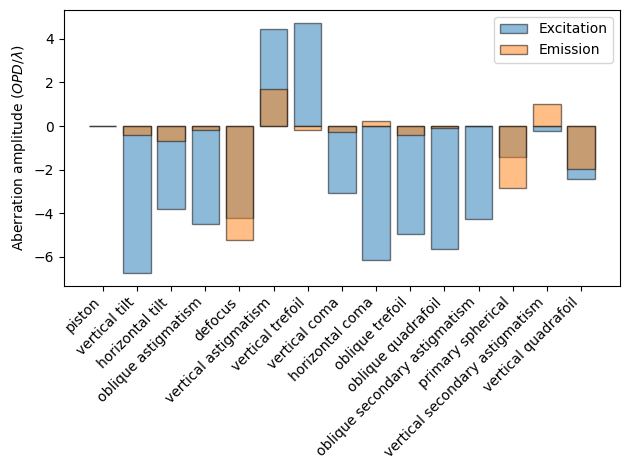

In [109]:
plt.figure()
plt.bar(zernike_idx, zernike_output_ex, alpha = 0.5, linewidth = 1, edgecolor = 'black', label = 'Excitation')
plt.bar(zernike_idx, zernike_output_em, alpha = 0.5, linewidth = 1, edgecolor = 'black', label = 'Emission')
plt.ylabel(r'Aberration amplitude ($OPD/\lambda)$')
plt.gca().set_xticks(zernike_idx)
plt.gca().set_xticklabels(names, rotation=45, ha = 'right')
plt.legend()
plt.tight_layout()

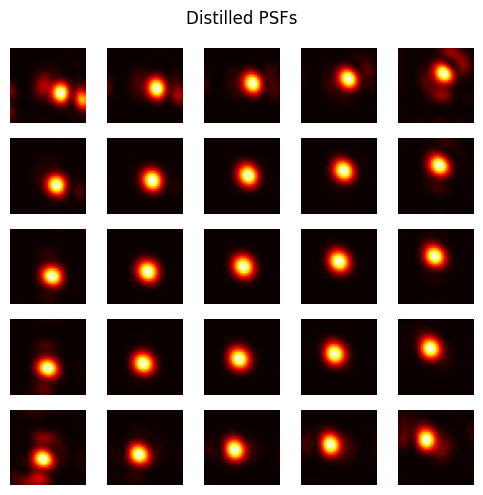

In [110]:
fit, *_ = sim.SPAD_PSF_2D(grid, exPar, emPar, spad=spad, process = process)
fig = ShowDataset(fit, figsize=(5,5))
fig.suptitle('Distilled PSFs')
fig.tight_layout()

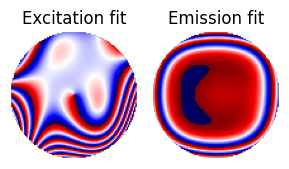

In [111]:
wavefront_fit_ex = exPar.wavefront

emPar.abe_index = zernike_idx
emPar.abe_ampli = zernike_output_em

wavefront_fit_em = emPar.wavefront

fig, ax = plt.subplots(1,2, sharex=True, sharey=True, figsize=(3,3))

ax[0].imshow(wavefront_fit_ex, cmap='seismic')
ax[0].axis('off')
ax[0].set_title('Excitation fit')

ax[1].imshow(wavefront_fit_em, cmap='seismic')
ax[1].axis('off')
ax[1].set_title('Emission fit')

fig.tight_layout()
# plt.savefig('em_wavefront.png', dpi = 300)

### Simulate PSF with vortex phase plate installed, assuming same aberrations as before

In [97]:
exPar.mask = 'vortex'
psf_vortex, *_ = sim.SPAD_PSF_2D(grid, exPar, emPar, spad=spad, process = process)

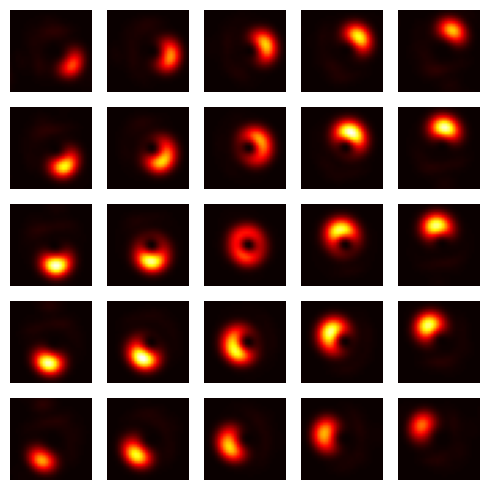

In [98]:
fig = ShowDataset(fit, figsize=(5,5), normalize=True)